# Numpy Exploration
Goal: get a first look at the loan data using Numpy before any cleaning and modelling 

## 1. Load the data

In [44]:
import sys
sys.path.append("../src")
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from loan_data import load_loans, clean, save_to_db, read_from_db

df = load_loans()
print(df.shape)
df

(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
255342,8C6S86ESGC,19,37979,210682,541,109,4,14.11,12,0.85,Bachelor's,Full-time,Married,No,No,Other,No,0
255343,98R4KDHNND,32,51953,189899,511,14,2,11.55,24,0.21,High School,Part-time,Divorced,No,No,Home,No,1
255344,XQK1UUUNGP,56,84820,208294,597,70,3,5.29,60,0.50,High School,Self-employed,Married,Yes,Yes,Auto,Yes,0
255345,JAO28CPL4H,42,85109,60575,809,40,1,20.90,48,0.44,High School,Part-time,Single,Yes,Yes,Other,No,0


## 2. Convert columns to numpy arrays 

In [45]:
income = df["Income"].to_numpy(dtype=float)
amount = df["LoanAmount"].to_numpy(dtype=float)
score = df["CreditScore"].to_numpy(dtype=float)

## 3. Default rate
The data is imbalanced with 11.6% default rate

In [46]:
default = df["Default"].to_numpy()
print(f"Default Rate: {np.mean(default ==1 ):.1%}")

Default Rate: 11.6%


## 4. Basic statistics (Income, LoanAmount, CreditScore)
Understanding aggregate functions

In [47]:
for name, x in [("Income",income),("LoanAmount",amount),("CreditScore",score)]:
    print(name,"mean",np.nanmean(x),"median",np.nanmedian(x),"std",np.nanstd(x),"min",np.nanmin(x),"max",np.nanmax(x))

Income mean 82499.30459727351 median 82466.0 std 38962.93743505733 min 15000.0 max 149999.0
LoanAmount mean 127578.86551242035 median 127556.0 std 70840.56742678002 min 5000.0 max 249999.0
CreditScore mean 574.2643461642392 median 574.0 std 158.90355544187352 min 300.0 max 849.0


## 5. percentile and boolean masks
Understanding percentile and Boolean masks

In [48]:
print(np.nanpercentile(income,[25,50,75,100]))
print("Loans above average amount",np.sum(amount > amount.mean()))
print("Low Credit score (<600)", np.sum(score < 600))

[ 48825.5  82466.  116219.  149999. ]
Loans above average amount 127648
Low Credit score (<600) 139483


## 6. Outliers

In [49]:
z = (income - income.mean())/income.std()
print("Income Outliers: ",np.sum(np.abs(z) > 3))

Income Outliers:  0


## 7. Missing values & corelation

In [50]:
print("Missing Values: ", np.isnan(income).sum())
print("Income vs LoanAmount",np.corrcoef(income,amount)[0, 1])

Missing Values:  0
Income vs LoanAmount -0.0008653256559258234


## 8. Comparsion

In [51]:
print("Avg Credit score: defaulted",score[default == 1].mean())
print("Avg Credit score: repaid",score[default == 0].mean())
print("Avg Interest rate: defaulted",df["InterestRate"].to_numpy()[default == 1].mean())
print("Avg Interest rate: repaid",df["InterestRate"].to_numpy()[default == 0].mean())

Avg Credit score: defaulted 559.2861430546657
Avg Credit score: repaid 576.2322702420091
Avg Interest rate: defaulted 15.896226688699288
Avg Interest rate: repaid 13.176993717156858


## What I noticed
- Default rate:
- Income and loan amount:
- Outliers:
- Credit score and interest rate, defaulted vs repaid:

# pandas cleaning
Goal: check data quality, fix data types, and save a cleaned copy. The original `loans.csv` is never changed.

## 1. Data quality checks (missing values, duplicates, ID)

In [52]:
print(df.isna().sum())
print(f"Duplicated records: {df.duplicated().sum()}")
df.describe().T


LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64
Duplicated records: 0


,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
LoanAmount,255347.0,127578.865512,70840.706142,5000.0,66156.00,127556.00,188985.00,249999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
MonthsEmployed,255347.0,59.541976,34.643376,0.0,30.00,60.00,90.00,119.0
NumCreditLines,255347.0,2.501036,1.117018,1.0,2.00,2.00,3.00,4.0
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0
LoanTerm,255347.0,36.025894,16.969330,12.0,24.00,36.00,48.00,60.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
Default,255347.0,0.116128,0.320379,0.0,0.00,0.00,0.00,1.0


## 2. Class balance

In [53]:
df["Default"].value_counts(normalize=True)

Default
0    0.883872
1    0.116128
Name: proportion, dtype: float64

## 3. Fix data types (Yes/No to 1/0, text to category)

In [54]:
for col in ["HasCoSigner", "HasDependents", "HasMortgage"]:
    df[col] = df[col].map({"Yes":1,"No":0})

In [55]:
for col in ["Education", "EmploymentType", "MaritalStatus", "LoanPurpose"]:
    df[col] = df[col].astype("category")
df.dtypes

LoanID                 str
Age                  int64
Income               int64
LoanAmount           int64
CreditScore          int64
MonthsEmployed       int64
NumCreditLines       int64
InterestRate       float64
LoanTerm             int64
DTIRatio           float64
Education         category
EmploymentType    category
MaritalStatus     category
HasMortgage          int64
HasDependents        int64
LoanPurpose       category
HasCoSigner          int64
Default              int64
dtype: object

## 4. Check for impossible values

In [56]:
print(f"Loan Takers Age less than 18: {(df["Age"]< 18).sum()},\nInvalid Income: {(df["Income"] <= 0).sum()}")
df[["Age", "Income", "CreditScore", "DTIRatio", "InterestRate"]].describe().T

Loan Takers Age less than 18: 0,
Invalid Income: 0


,count,mean,std,min,25%,50%,75%,max
Age,255347.0,43.498306,14.990258,18.0,31.00,43.00,56.00,69.0
Income,255347.0,82499.304597,38963.013729,15000.0,48825.50,82466.00,116219.00,149999.0
CreditScore,255347.0,574.264346,158.903867,300.0,437.00,574.00,712.00,849.0
DTIRatio,255347.0,0.500212,0.230917,0.1,0.30,0.50,0.70,0.9
InterestRate,255347.0,13.492773,6.636443,2.0,7.77,13.46,19.25,25.0


## 5. Drop the ID column and save the cleaned data

In [57]:
df_clean = df.drop(columns=["LoanID"])
df_clean.to_csv("../data/loans_clean.csv", index=False)
df_clean.head(5)

,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,1,1,Other,1,0
1,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,0,0,Other,1,0
2,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,1,1,Auto,0,1
3,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,0,0,Business,0,0
4,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,0,1,Auto,0,0


## Cleaning decisions
- Missing values:
- Duplicates:
- Columns dropped:
- Types changed:
- Class balance:
- Shape before and after:

## 6. groupby

In [58]:
for col in ["Education", "EmploymentType", "MaritalStatus", "LoanPurpose", "HasCoSigner"]:
    print(df.groupby(col)["Default"].agg(["mean", "count", "sum"]).sort_values("count"), "\n")

                 mean  count   sum
Education                         
PhD          0.105860  63537  6726
Master's     0.108717  63541  6908
High School  0.128789  63903  8230
Bachelor's   0.121011  64366  7789 

                    mean  count   sum
EmploymentType                       
Full-time       0.094634  63656  6024
Self-employed   0.114620  63706  7302
Unemployed      0.135529  63824  8650
Part-time       0.119652  64161  7677 

                   mean  count    sum
MaritalStatus                        
Single         0.119124  85012  10127
Divorced       0.125328  85033  10657
Married        0.103972  85302   8869 

                 mean  count   sum
LoanPurpose                       
Auto         0.118814  50844  6041
Other        0.117885  50914  6002
Education    0.118381  51005  6038
Home         0.102348  51286  5249
Business     0.123260  51298  6323 

                 mean   count    sum
HasCoSigner                         
0            0.128661  127646  16423
1       

In [59]:
df.groupby("Default")[["Age", "Income", "LoanAmount", "CreditScore", "InterestRate"]].mean().T

Default,0,1
Age,44.409962,36.559539
Income,83899.165995,71844.722659
LoanAmount,125353.656017,144515.311469
CreditScore,576.232270,559.286143
InterestRate,13.176994,15.896227


# Creation
* From clean function, we convert Yes/No to 1/0
* From save_to_db function, we save our data in our postgres database
* From read_from_db function, we read our data from postgres database and perform sql functions

In [60]:
df = clean(load_loans())
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,1,1,Other,1,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,0,0,Other,1,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,1,1,Auto,0,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,0,0,Business,0,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,0,1,Auto,0,0


In [61]:
save_to_db(df)

In [62]:
db_df = read_from_db()
print(db_df.shape)
db_df.head()

(255347, 18)


,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,1,1,Other,1,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,0,0,Other,1,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,1,1,Auto,0,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,0,0,Business,0,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,0,1,Auto,0,0


In [63]:
read_from_db('SELECT "Default","Education", COUNT(*) FROM loans GROUP BY "Default", "Education"')

,Default,Education,count
0,0,Bachelor's,56577
1,0,High School,55673
2,1,Bachelor's,7789
3,1,PhD,6726
4,0,PhD,56811
5,0,Master's,56633
6,1,Master's,6908
7,1,High School,8230


In [64]:
FIG = Path("../reports/figures")
FIG.mkdir(parents=True, exist_ok=True)

## 1. Class balance
**Question:** how many loans default compared with loans that are repaid?

About 11.6% of loans default (29,653 of 255,347), roughly 1 default for every 8 repaid loans. The data is imbalanced, so I will judge models on recall, F1 and ROC-AUC, not accuracy.

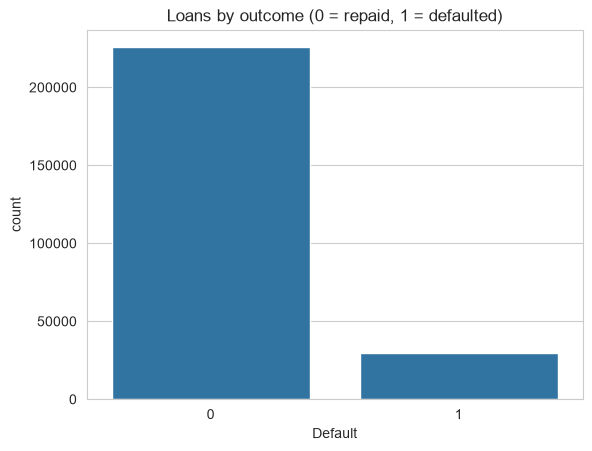

In [81]:
sns.set_style(style="whitegrid")
ax = sns.countplot(data=df, x="Default")
ax.set_title("Loans by outcome (0 = repaid, 1 = defaulted)")
plt.savefig(FIG / "01_class_balance.png",dpi=150,bbox_inches="tight")
plt.show()

## 2. Default rate by category
**Question:** do some groups default more than others?

Employment type shows the biggest gap: unemployed borrowers default at about 13.5% against about 9.5% for full-time. Education, marital status and loan purpose differ by only 2 to 3 percentage points, so they look like weaker signals.

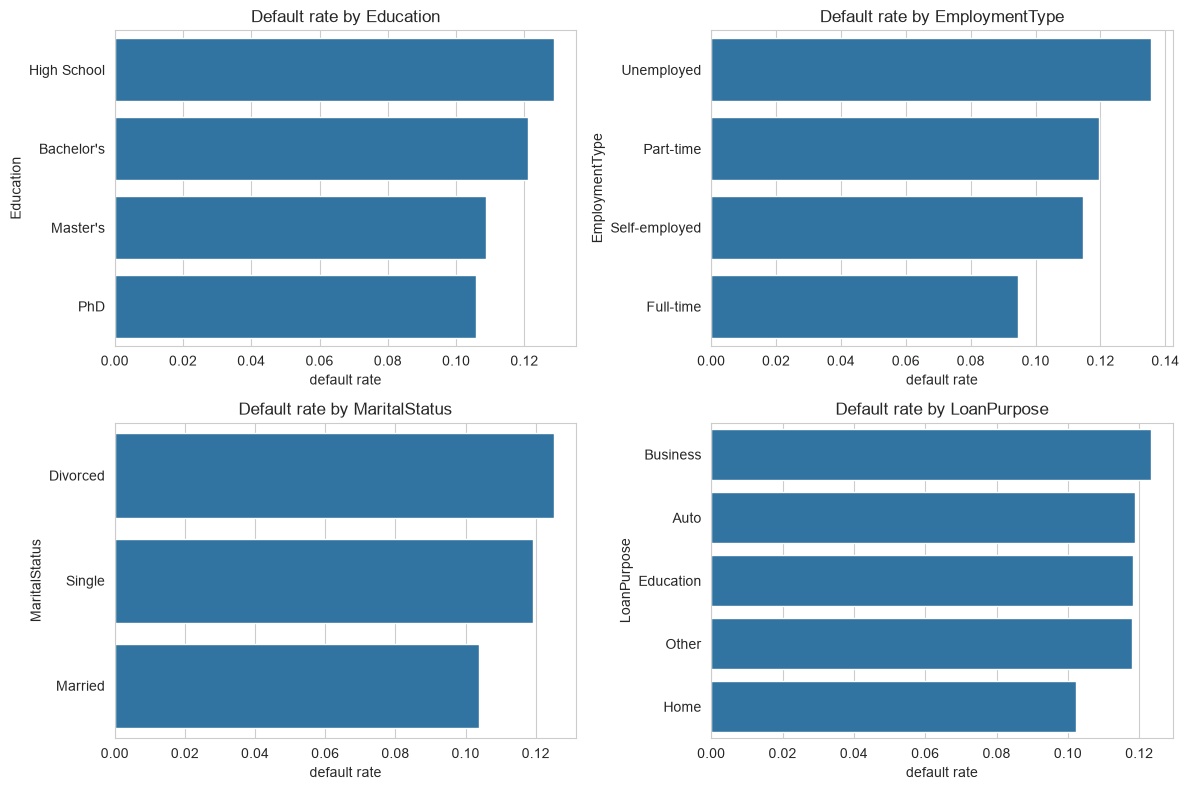

In [67]:
fig, axes = plt.subplots(2,2, figsize=(12,8))
for ax, col in zip(axes.ravel(),["Education", "EmploymentType",	"MaritalStatus","LoanPurpose"]):
    rate = df.groupby(col)["Default"].mean().sort_values(ascending=False)
    sns.barplot(x=rate.values, y=rate.index, ax=ax)
    ax.set_title(f"Default rate by {col}")
    ax.set_xlabel("default rate")
plt.tight_layout()
plt.savefig(FIG / "02_default_by_category.png",dpi=150)
plt.show();

## 3. Distributions: defaulted vs repaid
**Question:** which numeric features look different for defaulters (orange) compared with borrowers who repaid (blue)?

Each group is scaled separately (`common_norm=False`), so the chart compares the shape of each group, not how many loans it has. Where orange rises above blue, defaulters are more concentrated in that range.

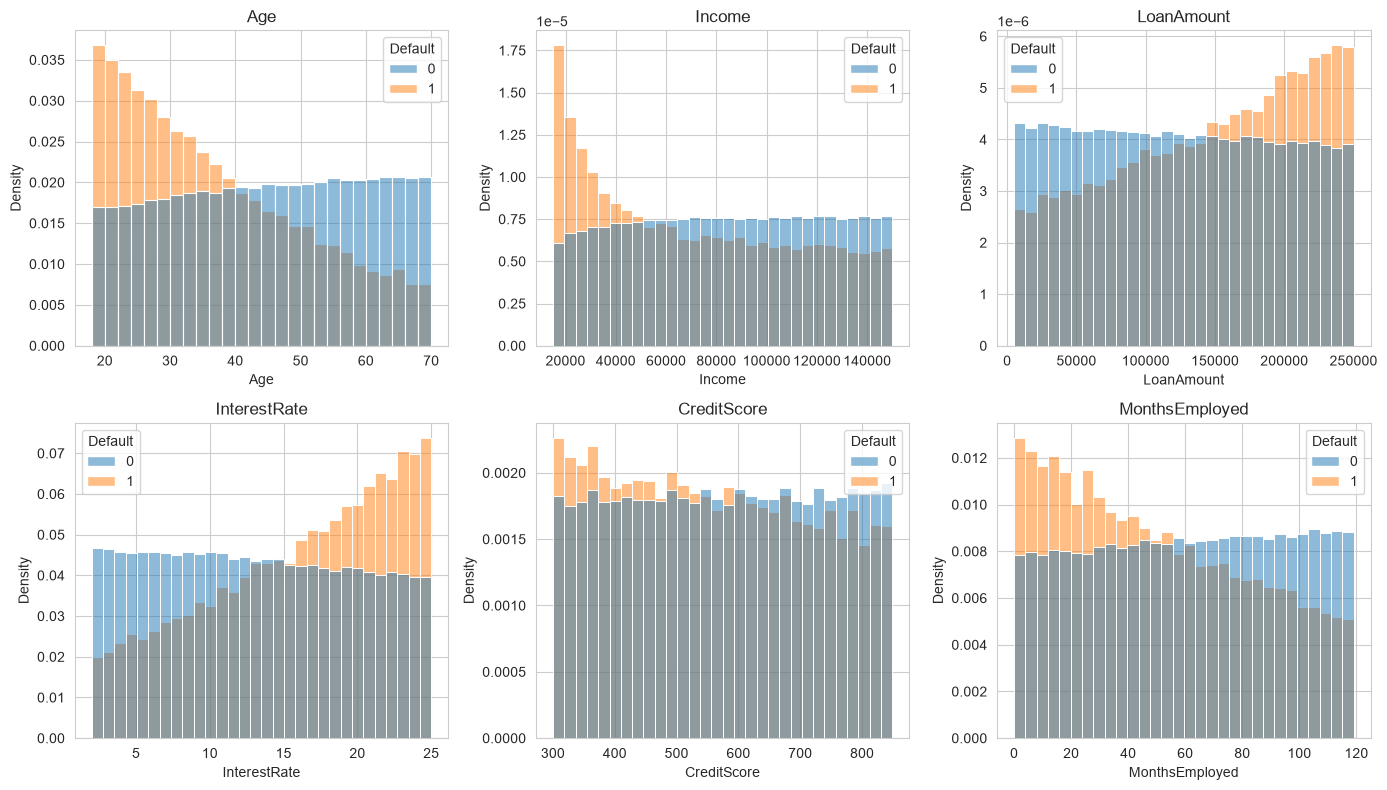

In [97]:
fig, axes = plt.subplots(2,3, figsize=(14,8))
for ax, col in zip(axes.ravel(),["Age", "Income", "LoanAmount", "InterestRate", "CreditScore", "MonthsEmployed"]):
    bins = np.arange(18,71,2) if col == "Age"  else 30
    sns.histplot(data=df, x=col, hue="Default",stat="density",common_norm=False, bins=bins, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.savefig(FIG / "03_distributions.png",dpi=150)
plt.show()

## 4. Default rate by age group
**Question:** does the default rate change with age?

Default rate falls steadily with age, from about 20.7% for ages 18-25 to about 5.5% for ages 56-69. Age is the strongest single signal I found. The `AgeGroup` column is only for this chart and will not be used for modelling.

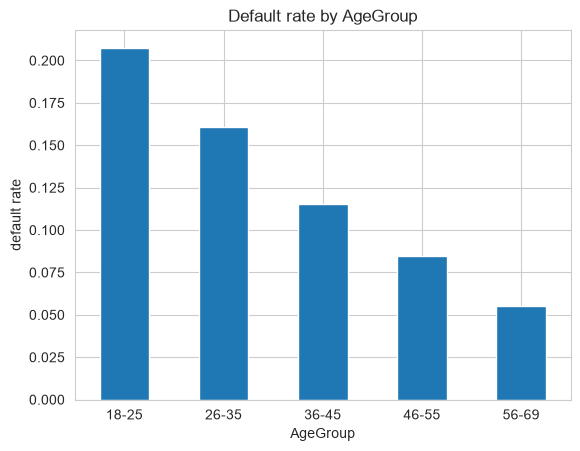

In [80]:
df["AgeGroup"] = pd.cut(df["Age"],bins=[17,25,35,45,55,70],labels=["18-25","26-35","36-45","46-55","56-69"])
rate = df.groupby("AgeGroup",observed=True)["Default"].mean()
ax = rate.plot(kind="bar",rot=0, title="Default rate by AgeGroup")
ax.set_ylabel("default rate")
plt.savefig(FIG / "04_default_by_age.png",dpi=150,bbox_inches="tight")
plt.show()

## 5. Correlation heatmap
**Question:** which numeric columns move with `Default`, and do any features repeat each other?

Age (-0.17) and interest rate (+0.13) have the strongest linear link with default, followed by income, months employed and loan amount (about 0.10 each). Credit score is only -0.03, which is unusual for credit data and suggests this dataset may be synthetic. The features are almost uncorrelated with each other, so none is redundant. Every correlation is small, so I expect no single feature to predict default well, and models will need to combine several. Correlation does not show cause.

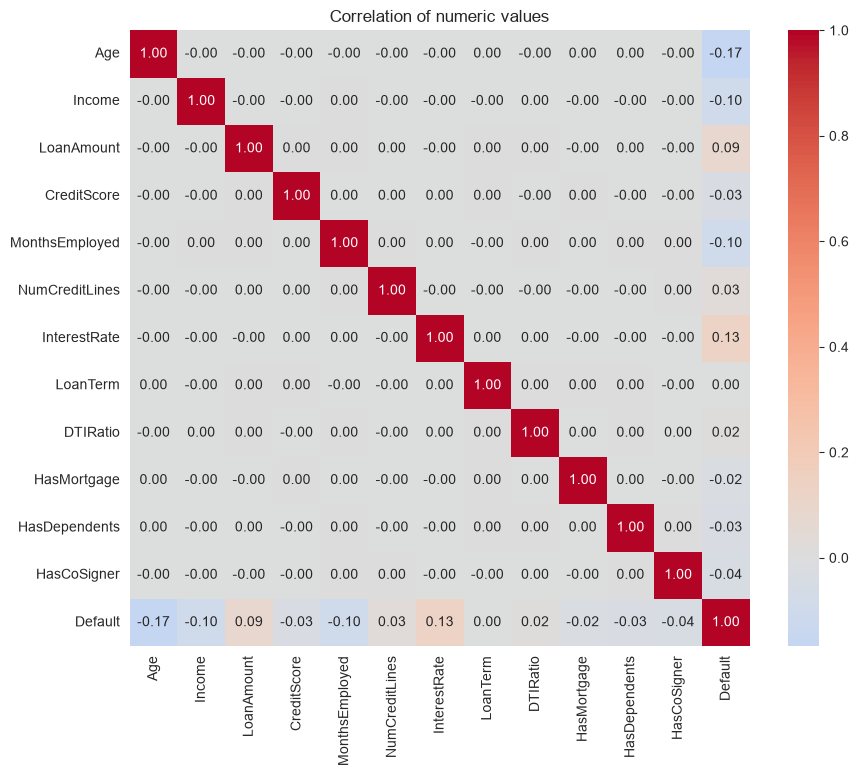

In [94]:
num = df.select_dtypes("number")
plt.figure(figsize=(10,8))
sns.heatmap(num.corr(),annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric values")
plt.savefig(FIG / "05_Correlation.png",dpi=150,bbox_inches = "tight")
plt.show()

**Finding:**
- **Age:** defaulters are concentrated among younger borrowers (under about 40). The pattern reverses after about 45.
- **Income:** a sharp spike of defaulters at the lowest incomes (about 15,000 to 40,000). Above about 70,000 the two groups are similar, with repaid slightly higher.
- **LoanAmount:** larger loans (above about 150,000) are more common among defaulters.
- **InterestRate:** defaulters are clearly more common above about 15%, and repaid loans dominate below it.
- **MonthsEmployed:** short employment (under about 45 months) is more common among defaulters.
- **CreditScore:** only a small difference, with slightly more defaulters below about 500.

The strongest separation comes from age, interest rate and low income. Many of these patterns switch at a tipping point instead of changing in a straight line, so tree-based models (random forest, gradient boosting) may capture them better than logistic regression.